Compare performance with traditional ML models by manually implementing evaluation metrics, analyzing overfitting tendencies, and explaining the advantages and limitations of deep learning over classical methods.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Target classes:", np.unique(y))

Dataset shape: (79, 6)
Target classes: [0 1]


In [12]:
np.random.seed(42)

train_indices = []
test_indices = []

for label in np.unique(y):
    indices = np.where(y == label)[0]
    np.random.shuffle(indices)

    split = int(0.8 * len(indices))
    train_indices.extend(indices[:split])
    test_indices.extend(indices[split:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

np.random.shuffle(train_indices)
np.random.shuffle(test_indices)

X_train_raw = X[train_indices]
X_test_raw = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 62
Testing records: 17


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

traditional_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "k-NN": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}

for name, model in traditional_models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
k-NN trained successfully


In [14]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, 1) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, 1))

Y_train = y_train.reshape(-1, 1)
loss_history = []
epochs = 500
learning_rate = 0.01

for epoch in range(epochs):
    z1 = X_train @ W1 + b1
    h1 = np.maximum(0, z1)

    z2 = np.clip(h1 @ W2 + b2, -30, 30)
    output = 1 / (1 + np.exp(-z2))

    loss = -np.mean(
        Y_train * np.log(output + 1e-8)
        + (1 - Y_train) * np.log(1 - output + 1e-8)
    )
    loss_history.append(loss)

    dz2 = (output - Y_train) / len(Y_train)
    dW2 = h1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    dz1 = (dz2 @ W2.T) * (z1 > 0)
    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

def neural_network_predict(X):
    h = np.maximum(0, X @ W1 + b1)
    z = np.clip(h @ W2 + b2, -30, 30)
    return (1 / (1 + np.exp(-z))).ravel()

print("Neural network training completed.")
print("Final training loss:", round(loss_history[-1], 4))

Neural network training completed.
Final training loss: 0.3924


In [15]:
def calculate_metrics(actual, predicted):
    tp = np.sum((actual == 1) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))

    accuracy = (tp + tn) / len(actual) * 100
    precision = tp / (tp + fp) * 100 if tp + fp else 0
    recall = tp / (tp + fn) * 100 if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return accuracy, precision, recall, f1


results = []

for name, model in trained_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_metrics = calculate_metrics(y_train, train_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    results.append({
        "Model": name,
        "Train Accuracy (%)": train_metrics[0],
        "Test Accuracy (%)": test_metrics[0],
        "Test Precision (%)": test_metrics[1],
        "Test Recall (%)": test_metrics[2],
        "Test F1 (%)": test_metrics[3]
    })

nn_train_pred = (neural_network_predict(X_train) >= 0.5).astype(int)
nn_test_pred = (neural_network_predict(X_test) >= 0.5).astype(int)

nn_train_metrics = calculate_metrics(y_train, nn_train_pred)
nn_test_metrics = calculate_metrics(y_test, nn_test_pred)

results.append({
    "Model": "Neural Network",
    "Train Accuracy (%)": nn_train_metrics[0],
    "Test Accuracy (%)": nn_test_metrics[0],
    "Test Precision (%)": nn_test_metrics[1],
    "Test Recall (%)": nn_test_metrics[2],
    "Test F1 (%)": nn_test_metrics[3]
})

results_df = pd.DataFrame(results)

print(results_df.round(2).to_string(index=False))

              Model  Train Accuracy (%)  Test Accuracy (%)  Test Precision (%)  Test Recall (%)  Test F1 (%)
Logistic Regression               87.10              76.47               80.00            92.31        85.71
      Decision Tree              100.00              76.47               84.62            84.62        84.62
               k-NN               82.26              70.59               75.00            92.31        82.76
     Neural Network               88.71              76.47               80.00            92.31        85.71


In [16]:
results_df["Accuracy Gap (%)"] = (
    results_df["Train Accuracy (%)"]
    - results_df["Test Accuracy (%)"]
)

print("Overfitting Analysis")
print(results_df[
    ["Model", "Train Accuracy (%)", "Test Accuracy (%)", "Accuracy Gap (%)"]
].round(2).to_string(index=False))

for _, row in results_df.iterrows():
    gap = row["Accuracy Gap (%)"]

    if gap > 10:
        print(row["Model"], ": Possible overfitting.")
    elif gap > 5:
        print(row["Model"], ": Some training-testing gap.")
    else:
        print(row["Model"], ": Small training-testing accuracy gap.")

Overfitting Analysis
              Model  Train Accuracy (%)  Test Accuracy (%)  Accuracy Gap (%)
Logistic Regression               87.10              76.47             10.63
      Decision Tree              100.00              76.47             23.53
               k-NN               82.26              70.59             11.67
     Neural Network               88.71              76.47             12.24
Logistic Regression : Possible overfitting.
Decision Tree : Possible overfitting.
k-NN : Possible overfitting.
Neural Network : Possible overfitting.


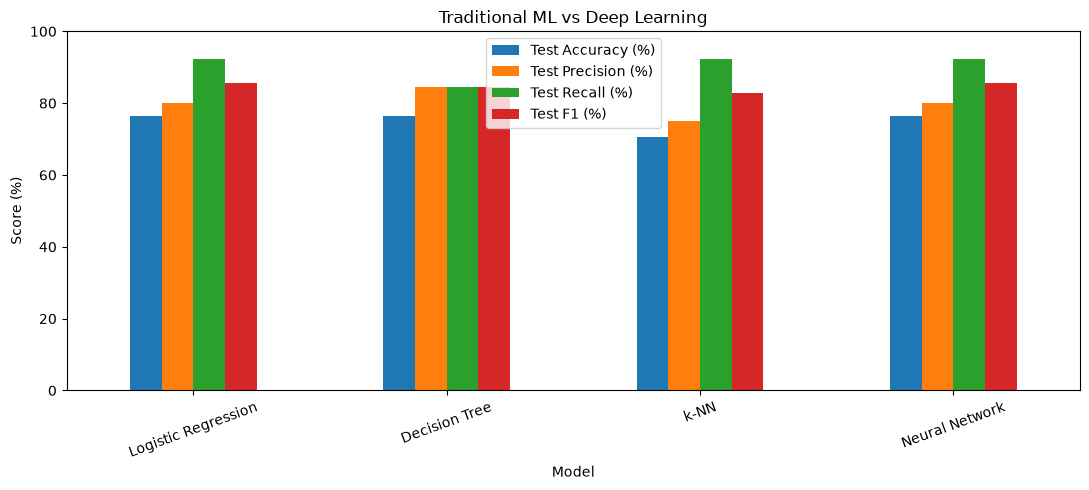

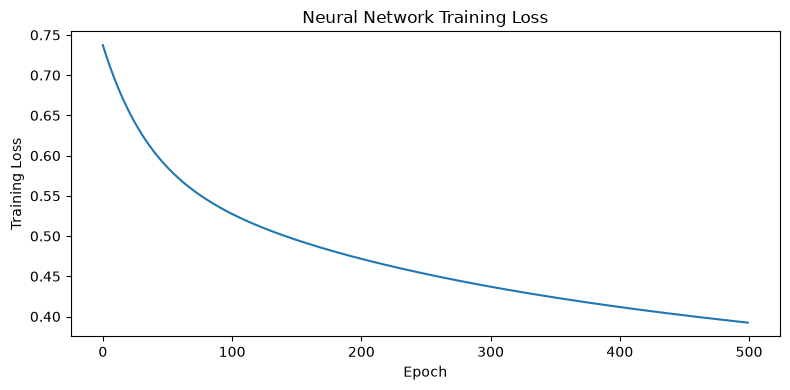

In [17]:
metrics = [
    "Test Accuracy (%)",
    "Test Precision (%)",
    "Test Recall (%)",
    "Test F1 (%)"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(11, 5)
)

plt.title("Traditional ML vs Deep Learning")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Neural Network Training Loss")
plt.tight_layout()
plt.show()

In [18]:
best_accuracy = results_df.loc[
    results_df["Test Accuracy (%)"].idxmax(), "Model"
]

best_recall = results_df.loc[
    results_df["Test Recall (%)"].idxmax(), "Model"
]

best_f1 = results_df.loc[
    results_df["Test F1 (%)"].idxmax(), "Model"
]

print("Final Model Comparison")
print("----------------------")
print("Highest test accuracy:", best_accuracy)
print("Highest test recall:", best_recall)
print("Highest test F1-score:", best_f1)

print("\nConclusion")
print("Traditional ML models and a manually implemented neural network")
print("were compared using the same training and test data.")
print("Performance metrics were calculated manually.")
print("Training and testing accuracy were compared to identify")
print("possible overfitting.")

Final Model Comparison
----------------------
Highest test accuracy: Logistic Regression
Highest test recall: Logistic Regression
Highest test F1-score: Logistic Regression

Conclusion
Traditional ML models and a manually implemented neural network
were compared using the same training and test data.
Performance metrics were calculated manually.
Training and testing accuracy were compared to identify
possible overfitting.
